=========================[STEP: Select preferences]=========================
Would you like to generate the same amount of samples as the dataset or a fixed number of samples?
Please select one of the following:
1. fixed value
2. same as original



Are you interested in differential privacy?

Is there a specific data generator that you want to use on your data? Select 'auto' if you would
like a suggestion.
Please select one of the following:
1. auto
2. PATEGAN
3. CTGAN
4. PrivBayes
5. BayesianNet
	🠊 You will receive a recommendation based on the dataset's characteristics.

How would you like missing values to be handled? Select 'auto' if you would like a suggestion.
Please select one of the following:
1. auto
2. impute
3. remove
	🠊 You will receive a recommendation based on the dataset's characteristics.

-------------------------Your preferences have been recorded-------------------------

Sample size mode: same_as_original
Privacy mode: differential_privacy
Generator: auto
Missing value handling: auto



=========================[STEP: Normalize missing values]=========================

🠊 No potential missing value markers have been detected in the dataset.



=========================[STEP: Handle data types]=================

Categories {nan} in column 'deck' are in real data but not in synthetic data. They will not be considered in the score computation.
Categories {nan} in column 'embarked' are in real data but not in synthetic data. They will not be considered in the score computation.
Removed 245 entries due to missing values.


survived 0.0683
pclass 0.3728
sex 0.1029
age 0.4593
sibsp 0.8216
parch 0.3616
fare 0.7024
embarked 0.343
class 0.1941
who 0.3099
adult_male 0.4544
deck 0.3635
embark_town 0.5671
alive 0.228
alone 0.0246
jsd_AVERAGE 0.3582

Normalized correlation difference: 0.5137

Discriminator AUC: 1.0

Evaluating singling out risk...

🠊 Singling out risk:
 - Value: 0.495%
  - Confidence interval: between 0.0% and 1.404%

Agent is selecting columns for the following privacy metrics to be assessed:
- Inference risk
- Linkability risk
Columns selected for the following privacy metric calculation:
- Linkability:
  - First auxiliary set: sex, age, embarked, and embark_town
  - Second auxiliary set: pclass, fare, sibsp, parch, and class
- Inference:
  - Auxiliary columns: pclass, sex, age, sibsp, parch, fare, embarked, class, who, adult_male, deck, embark_town, and alone
  - Secret column: survived

Rationale:
Linkability uses common quasi-identifiers split into demographic/travel-origin and ticket/family

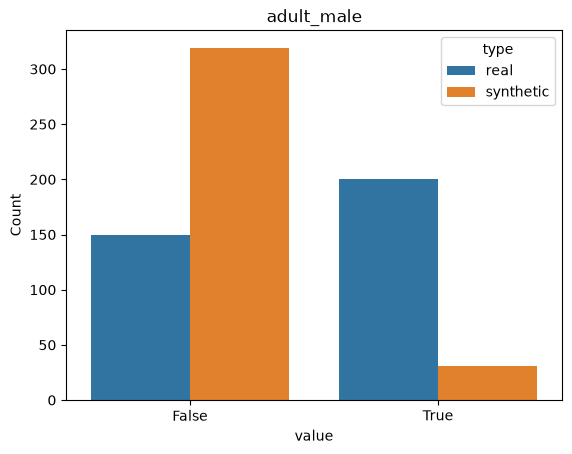

🠊 Distributions plots saved to: /home/alewis/Downloads/agentic-synth-data/output/version_1/plots/distributions

Correlations plot: real_corr.png


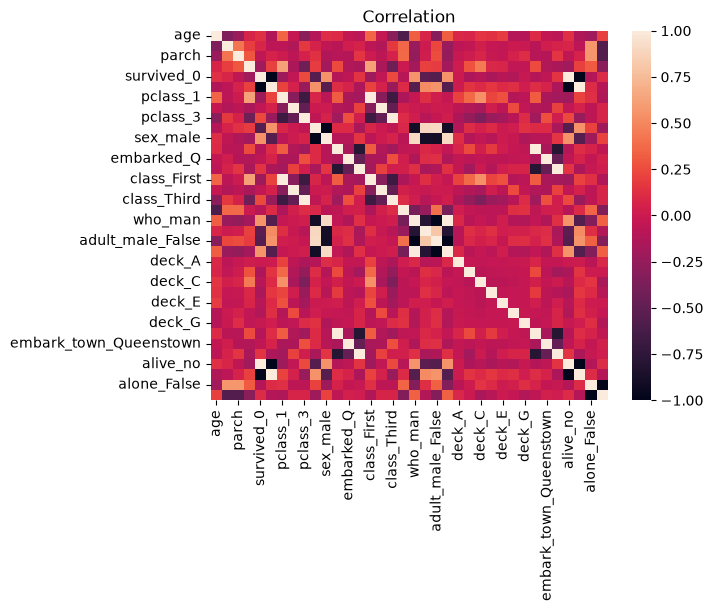

🠊 Correlations plots saved to: /home/alewis/Downloads/agentic-synth-data/output/version_1/plots/correlations

Shap plot: shap_discrimination.png


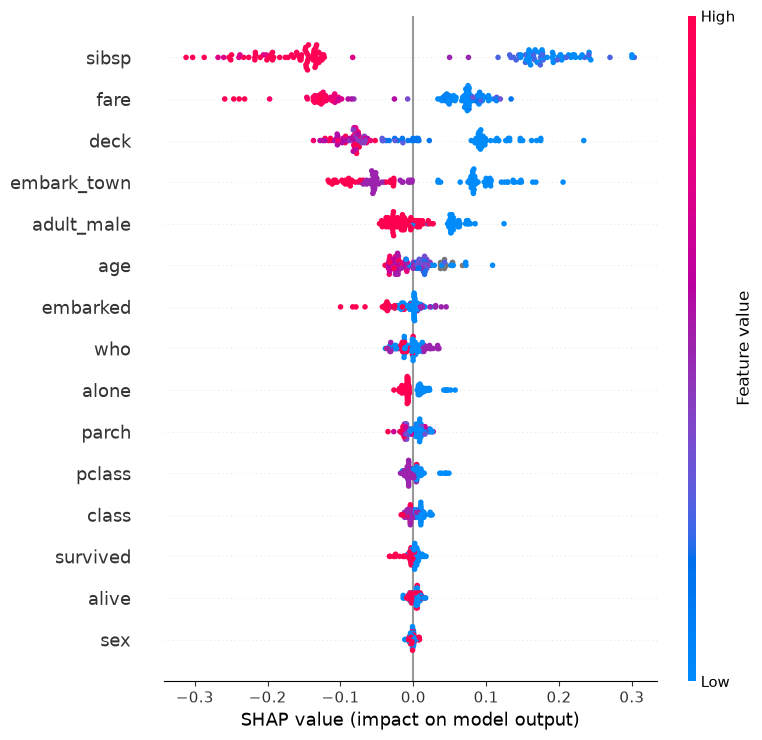

🠊 Shap plots saved to: /home/alewis/Downloads/agentic-synth-data/output/version_1/plots/shap

Agent is evaluating the results...

Evaluation:
- Status: not_satisfactory
- Problem columns: sibsp, fare, and embark_town
- Recommendation:
Revisit generator selection/parameters (workflow step 3c). PrivBayes with degree=1 and epsilon=0.1
is too restrictive for the fare, sibsp, and embark_town distributions and their dependencies. If the
privacy budget permits, increase epsilon or degree, or evaluate PATEGAN for the mixed
numeric/categorical structure. Also consider revisiting missing value handling (step 3d) because
missing categories in deck and embarked are not represented in the synthetic data.
- Rationale:
Fidelity is poor: average JSD is 0.3582, well above the 0.25 threshold, with sibsp (0.8216), fare
(0.7024), and embark_town (0.5671) as clear problem columns. Normalized correlation difference is
0.5137, indicating weak preservation of relationships such as fare/pclass and sibsp/parch,

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,59.989293,4,0,424.828428,Q,First,man,False,C,Cherbourg,yes,False
1,0,1,male,49.294814,4,1,14.953242,S,Third,man,False,D,Queenstown,yes,False
2,1,1,female,65.557645,4,3,433.108548,Q,Third,man,False,F,Cherbourg,yes,False
3,1,1,male,39.629679,3,0,295.202220,C,First,child,False,C,Cherbourg,no,True
4,1,3,female,12.977226,4,3,413.786018,Q,First,child,False,E,Cherbourg,yes,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
345,1,1,female,35.948147,4,1,425.803371,Q,First,man,False,G,Queenstown,yes,True
346,0,1,female,13.544256,4,0,445.805531,Q,First,child,False,B,Cherbourg,yes,True
347,0,1,male,39.190657,4,0,418.263238,Q,Third,child,False,F,Cherbourg,yes,True
348,0,1,male,44.410078,4,0,32.480262,S,First,man,False,C,Queenstown,yes,False


In [2]:
from agentic_synth_data.workflow import DataGen

# Dataset path
data_path = "../demo_data/mix_titanic.csv" # (mix of categorical and numerical)

# Input initial dataset
gen = DataGen(data_path)

# Run workflow
gen.run()